<a href="https://colab.research.google.com/github/Marc0s-ikp/imperial_eee_machine_learning_course-main/blob/master/04_ML_Logistic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression


---

Despite of the efficiency of the perceptron algorithm in binary classification tasks; however, the algorithm never converges when the data are not linearly seperable. Logistic regression is a supervised ML algorithm that is used in binary classification problems. The algorithm converts the linear model predictions into a probability between 0 and 1. For better understanding of this algorithm, let us recall the odds ratio, which is the odds in favour of a particular event to occur. The odds ratio can be formulated as $\frac{p}{1-p}$, where $p$ is the probability of a positive event (the event that we want to predict e.g. $y = 1$). Let us now extend our previous discussion and define the logit function, which is simply the logarithm of the odds ratio (log-odds) given by the following equation:

\begin{equation}
logit(p) = \log \left(\frac{p}{1-p}\right)
\end{equation}

As $p$ is a probability, the logit function takes a value between 0 and 1 and transforms them to values over the entire real number range, which we can use to express a linear relationship between feature values and the log-odds.

\begin{equation}
logit\left(p\left(y=1|\mathbf{x}\right)\right)=w_0x_0 + w_1x_1 + \ldots + w_nx_n = \sum_{i=0}^{n} w_nx_n
\end{equation}

Hence, $p\left(y=1|\mathbf{x}\right)$ is the probability of a sample point that belongs to class 1 given its features $x$. However, in the learning process, we are more interested in the opposite case such that predicting the probability that a certain sample belongs to a particular class, which is simply the inverse of the logit function. The inverse of the logit function is called the $logistic$ function (also know as $Sigmoid$ function). The Sigmoid function is given by the equation below:

\begin{equation}
\sigma(z) = \frac{1}{1+e^{-z}}
\end{equation}

Hence, $z$ is the net input, that is, the linear combination of weights and sample features such that $z = \sum_{i=0}^{n} w_nx_n$. The Sigmoid function can be further visualised and plotted using the figure below:

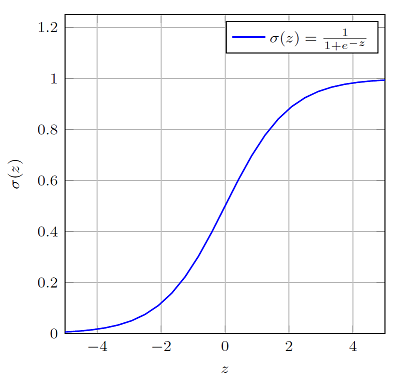

From the figure above we can observe that the Sigmoid function is bouned between 0 and 1. Such that if $z$ goes toward infinity ($z \to \infty$) then $\sigma(z)=\frac{1}{1+e^{-\infty}}=1$, and on the other hand when $z$ goes toward minus infinity ($z \to -\infty$) then $\sigma(z)=\frac{1}{1+e^{\infty}}=0$. Thus, we conclude that sigmoid function takes real number values as input and transforms them to values in the range [0,1] with $\sigma(0) = 0.5$.

In logistic regression, the activation function simply becomes the sigmoid function that we defined earlier, which is illustrated in the following figure:

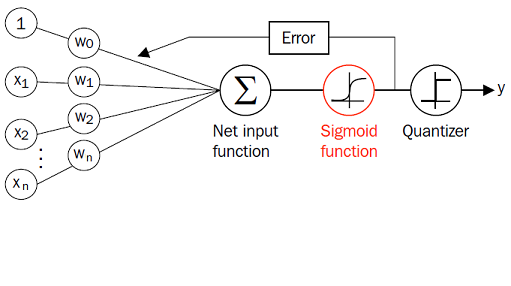

The output of the Sigmoid activation function is interpreted as the probability of particular sample belonging to class 1 $\sigma(z)=p\left(y=1|\mathbf{x,w}\right)$ given set of features $x$ and set of weights $w$. For instance, assume we have a binary classifier to classify samples of Iris-Versicolor ($y=1$) vs. Iris-Setosa ($y=0$). Then if we compute $\sigma(z)=0.9$, it means that the chance that this sample is an Iris-Versicolor flower is $90\%$. Similarly, the probability that this flower is an Iris-Setosa flower can be calculated as $p\left(y=0|\mathbf{x,w}\right) = 1 - p\left(y=1|\mathbf{x,w}\right) = 0.1$ or $10\%$.


So far we have discussed how Logistic regression makes predictions, but we did not talk about the cost function and learning process. Unlike the case in linear regression where we used MSE cost function, in logistic regression we use log-loss (also known as binary cross entropy (BCE)), given by the equation below:

\begin{equation}
    J(w)=\frac{1}{N} \sum_{i=1}^{N} [-y_{i}\cdot\log\left(\hat{y}_{i}\right)-\left(1-y_{i}\right)\cdot\log\left(1-\hat{y}_{i}\right)]
\end{equation}
where $y_{i}$ is the label  for training example $i$, $\hat{y}_{i}$ is the predicted class by applying the hypothesis or $\sigma(z)$.


For more information why we chose BCE over MSE, please refer to the lecture notes

Our main aim is to minimise our BCE cost function in order to get accurate predictions. In order to do that, we keep updating the parameter $w$ in the direction that minimises the cost function. The amount of change that we modify $w$ is called the gradient and is given by differentiating the cost function with respect to $w$. We can control how fast this gradient step is moving by introducing the learning rate ($\alpha$). This process is called Gradient Descent and is illustrated in the figure below:

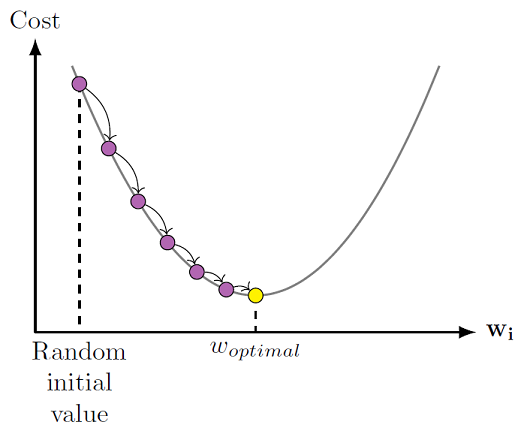


When the training is done and we want to predict the output using test data, the predicted probability can be converted into a binary outcome via a quantizer (unit step function) such that:

\begin{equation}
y_{pred} = \begin{cases}
      1 & \hat{y}\geq 0.5 \\
      0 & otherwise
   \end{cases}
\end{equation}


Reference:
"Python Machine Learning," Sebastian Raschka, Packt Publishing, 2015


# Data Used & Problem Definition

We will use logistic regression as a binary classifier between Setosa vs other classes (verginica and versicolor grouped together). Here we say that data points with features that result in output probabilities closer to 0 are likely Setosa, while values closer to 1 are likely not Setosa. For simplicity, we will consider two features, petal length and sepal length, which can be visualised in a 2D plot.

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
import pandas as pd

In [28]:
iris = datasets.load_iris()

In [29]:
iris_data = pd.DataFrame(data=iris['data'],columns=iris['feature_names'])
iris_data["target"] = iris['target']

In [30]:
iris_data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [31]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

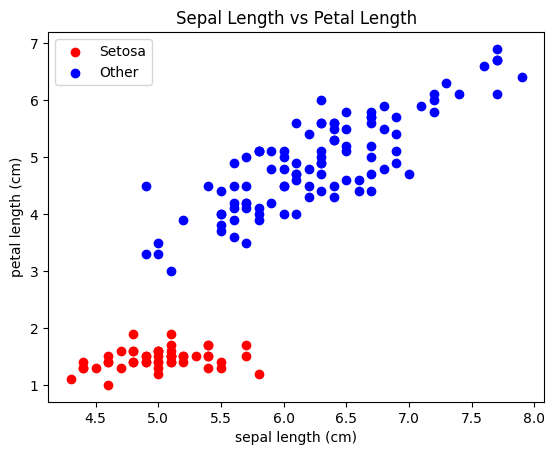

In [32]:
# Target labels are the index in iris.target_names
labels = iris_data.iloc[:,4]

# Setosa is assigned label 0, while all other classes will have a label of 1
y = np.where(labels == 0, 0, 1)

# Consider only two features - sepal length (column 0) and petal length (column 2)
# Bias term (intercept) is added to each data point (row)
X = iris_data.iloc[:,[0,2]]
intercept = np.ones((X.shape[0], 1))
X = np.concatenate((intercept, X), axis=1)

# Plot features in 2D plot - sepal length (x-axis) vs petal length (y-axis)
feat1, feat2 = 'sepal length (cm)', 'petal length (cm)'
X_target = iris_data[iris_data.target==0]
X_other = iris_data[iris_data.target!=0]

plt.scatter(X_target[feat1],X_target[feat2],color='red',marker='o',label="Setosa")
plt.scatter(X_other[feat1],X_other[feat2],color='blue',marker='o',label='Other')
plt.title("Sepal Length vs Petal Length")
plt.xlabel(feat1)
plt.ylabel(feat2)
plt.legend(loc='upper left')
plt.show()

In [33]:
def sigmoid(z):
    # Sigmoid function
    return 1 / (1 + np.exp(-z))

In [34]:
def cost(Y, y):
    # log-loss or Binary Cross Entropy (BCE)
    eps = 1e-15 # to avoid numerical error at log(0)
    return (-y * np.log(Y+eps) - (1 - y) * np.log(1 - Y + eps)).mean()

In [35]:
def plot_cost(loss):
    # Function for plotting the cost vs iterations.
    plt.plot(range(1, len(loss) + 1), loss)
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    # plt.savefig('plot.pdf')
    plt.show()

In [36]:
def predict(X, W):
    # Function for predicting on test data (see Task 1)
    prediction = sigmoid(np.dot(X, W))
    return prediction.round()

In [37]:
def fit(alpha, num_iter, X, y):
    # weights initialization
    W = np.zeros(X.shape[1])
    loss_list = []
    for i in range(num_iter):
        # Feed forward
        z = np.dot(X, W)
        Y = sigmoid(z)
        # Gradient
        W += alpha * (np.dot(X.T, (y-Y)) / y.size)
        loss = cost(Y, y)
        loss_list.append(loss)

        if i % 100 == 0:
            print(f'iteration: {i+1} \t', f'cost: {loss} \t', f'weights: {W} \t')
    plot_cost(loss_list)
    # This function will return the final weights as an array
    return W

iteration: 1 	 cost: 0.6931471805599433 	 weights: [0.00166667 0.01253    0.01391667] 	
iteration: 101 	 cost: 0.39716904888478627 	 weights: [-0.05071148 -0.07762237  0.42536019] 	
iteration: 201 	 cost: 0.29984517309777964 	 weights: [-0.10551432 -0.23097319  0.68989714] 	
iteration: 301 	 cost: 0.2382094249373507 	 weights: [-0.14864573 -0.34969591  0.90262115] 	
iteration: 401 	 cost: 0.196815362215292 	 weights: [-0.18374873 -0.44513976  1.07818086] 	
iteration: 501 	 cost: 0.1674853678274873 	 weights: [-0.21316007 -0.52436457  1.22669262] 	
iteration: 601 	 cost: 0.14576052746256243 	 weights: [-0.23838792 -0.5918273   1.3549739 ] 	
iteration: 701 	 cost: 0.12908024748143987 	 weights: [-0.26043675 -0.65044743  1.46769223] 	
iteration: 801 	 cost: 0.11589461609963037 	 weights: [-0.27999968 -0.70221333  1.56813002] 	
iteration: 901 	 cost: 0.1052199140543055 	 weights: [-0.29757115 -0.74852835  1.65866121] 	
iteration: 1001 	 cost: 0.0964055186179073 	 weights: [-0.31351439 -0.7

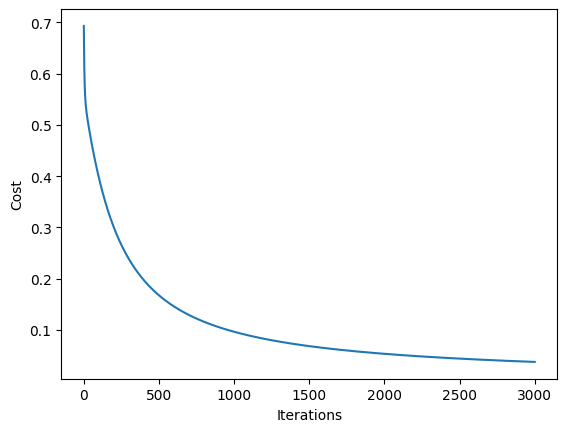

In [38]:
alpha = 0.01
num_iter = 3000
model_weights = fit(alpha, num_iter, X,y)

In [39]:
predictions = predict(X, model_weights)
pred = predictions.astype('int')
true = y.astype('int')

# Evaluation Metrics

Evaluation metrics are used to measure the performance of machine learning models. It is very important to evaluate the model after training takes place to decide whether the model can be implemented in the project or not. There are a variety of techniques used for evaluation such as classification accuracy, loss and confusion matrix. Confusion matrix is very useful tool for evaluation. It visualises the predictions for a classification problem against the real labels in table format.  Each row of the matrix represents the instances of real labels while each column represents the instances of predicted labels. The values of the confusion matrix are denoted by four categories, namely, true positive (TP), true negative (TN), false negative (FN) and false positive (FP). The outcomes of a confusion matrix can be visualised in Figure


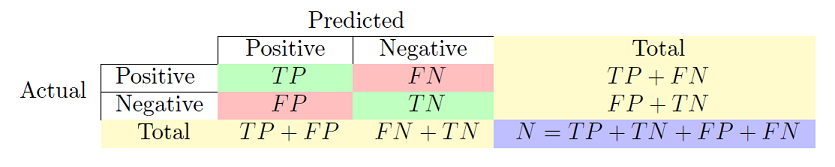

In [40]:
def compute_confusion_matrix(true, pred):

    num_cls = len(np.unique(true)) # Number of classes
    result = np.zeros((num_cls, num_cls))

    for i in range(len(true)):
        result[true[i]][pred[i]] += 1

    return result

conf_matrix = compute_confusion_matrix(true, pred)
print('Confusion matrix result: ')
print(conf_matrix)

diagonal_sum = conf_matrix.trace()
sum_of_all_elements = conf_matrix.sum()
accuracy = diagonal_sum / sum_of_all_elements
print('accuracy = {:0.2f}%'.format(accuracy*100))

Confusion matrix result: 
[[ 50.   0.]
 [  0. 100.]]
accuracy = 100.00%


## Task 1 [40 marks]

In the provided code, the network's performance was assessed using the same training dataset for both training and evaluation, which is not a recommended practice in evaluating machine learning algorithms. Your task is to adjust the code to split the data into two separate sets: a training set and a testing set. The training set should account for 80% of the original data, while the remaining 20% will constitute the test data. Additionally, you should address the following points:

1. Discuss the significance of using two distinct datasets (training and testing) when evaluating a machine learning algorithm.

2. Provide the code you used to divide the original dataset into the training and testing datasets. Ensure that the split is random and maintains data integrity.

3. After modifying the code and training the model on the training dataset, calculate the confusion matrix and total accuracy of the algorithm using the testing dataset. Include these performance metrics to assess the model's effectiveness in classifying data.



A model is only useful if it works on data it hasn’t seen, and the training set can’t tell you that. The weights were chosen specifically to fit the training samples, so the training error is an optimistically biased estimate of the true error. A flexible enough model can drive training error close to zero just by memorising noise, as the high-degree fits in the NLFT task showed, while doing worse on new points. If you train and evaluate on the same data, you can’t tell a model that has learned the real pattern from one that has overfitted.

A separate test set fixes this because it plays no part in training, so the model is effectively scored on fresh samples from the same distribution. That ties into Lecture 2. For a hypothesis fixed before you look at the test data, Hoeffding’s inequality bounds how far the test error can be from the true error, and the bound tightens as the test set grows. The same bound doesn’t apply to training error, because the hypothesis was picked using that data. The test set must also stay untouched until the end. If you use it to tune hyperparameters such as α or k, it becomes part of model selection and stops being an unbiased estimate. That’s the job of a validation set or cross-validation.

In [41]:
def train(alpha, num_iter, X, y, print_every=None):
    W = np.zeros(X.shape[1])
    loss_list = []
    for i in range(num_iter):
        Y = sigmoid(np.dot(X, W))
        W += alpha * (np.dot(X.T, (y - Y)) / y.size)
        loss = cost(sigmoid(np.dot(X, W)), y)
        loss_list.append(loss)
        if print_every and i % print_every == 0:
            print(f'iteration: {i+1} \t cost: {loss:.6f} \t weights: {W}')
    return W, loss_list

def confusion_matrix_2(true, pred):
    # 2x2 confusion matrix (rows = true class 0/1, columns = predicted class 0/1).
    # Fixed size so it still works if a class is missing from the test set.
    cm = np.zeros((2, 2), dtype=int)
    for t, p in zip(true, pred):
        cm[int(t)][int(p)] += 1
    return cm

def evaluate(X_test, y_test, W, title=''):
    pred = predict(X_test, W).astype(int)
    cm = confusion_matrix_2(y_test.astype(int), pred)
    acc = np.trace(cm) / cm.sum()
    return cm, acc

In [42]:

# Task 1
def train_test_split_np(X, y, strata, test_ratio=0.2, seed=0):
    rng = np.random.default_rng(seed)
    test_idx = []
    for c in np.unique(strata):
        idx_c = rng.permutation(np.where(strata == c)[0])
        test_idx.extend(idx_c[:int(round(test_ratio * len(idx_c)))])
    test_idx = np.sort(np.array(test_idx))
    train_idx = np.setdiff1d(np.arange(len(y)), test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx], train_idx, test_idx

X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split_np(X, y, labels.values, 0.2, seed=0)
print(f"Training samples: {len(y_train)}  (Setosa: {np.sum(y_train==0)}, Other: {np.sum(y_train==1)})")
print(f"Testing samples:  {len(y_test)}  (Setosa: {np.sum(y_test==0)}, Other: {np.sum(y_test==1)})")
print("No overlap between sets:", len(np.intersect1d(train_idx, test_idx)) == 0)

Training samples: 120  (Setosa: 40, Other: 80)
Testing samples:  30  (Setosa: 10, Other: 20)
No overlap between sets: True


iteration: 1 	 cost: 0.659663 	 weights: [0.00166667 0.01260833 0.0139625 ]
iteration: 501 	 cost: 0.166073 	 weights: [-0.21552333 -0.52044113  1.22767045]
iteration: 1001 	 cost: 0.095262 	 weights: [-0.31694718 -0.78461055  1.74233341]
iteration: 1501 	 cost: 0.067317 	 weights: [-0.38063854 -0.94794443  2.0702474 ]
iteration: 2001 	 cost: 0.052371 	 weights: [-0.4270873  -1.06627788  2.31140316]
iteration: 2501 	 cost: 0.043043 	 weights: [-0.46366262 -1.15917139  2.50250559]
Final weights: [-0.49378222 -1.23556583  2.66071907]


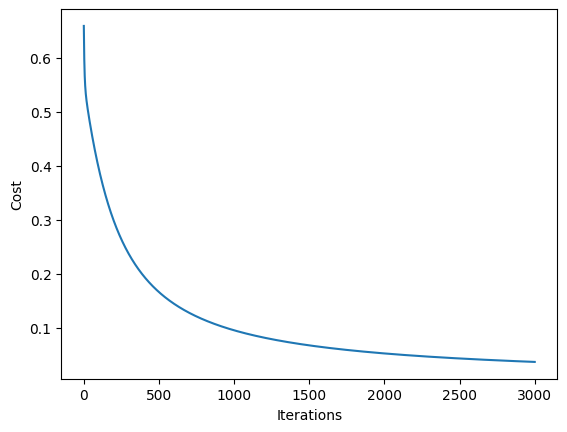

In [43]:
alpha = 0.01
num_iter = 3000
W_setosa, loss_setosa = train(alpha, num_iter, X_train, y_train, print_every=500)
print("Final weights:", W_setosa)
plot_cost(loss_setosa)

Confusion matrix (test set) — rows: true [Setosa, Other], columns: predicted [Setosa, Other]
[[10  0]
 [ 0 20]]
Test accuracy = 100.00%


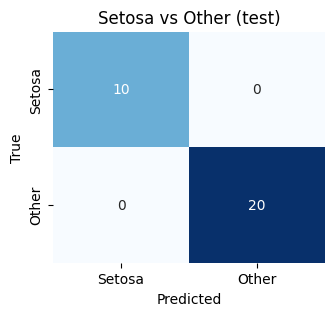

In [44]:
cm, acc = evaluate(X_test, y_test, W_setosa)
print('Confusion matrix (test set) — rows: true [Setosa, Other], columns: predicted [Setosa, Other]')
print(cm)
print('Test accuracy = {:0.2f}%'.format(acc * 100))

plt.figure(figsize=(3.5, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Setosa', 'Other'], yticklabels=['Setosa', 'Other'])
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Setosa vs Other (test)')
plt.show()

## Task 2 [20 marks]

In the provided code, the primary objective was to classify Iris-Setosa versus other classes. Your task is to modify the code so that it can classify Iris-Versicolor versus other classes and Iris-Virginica versus other classes separately. For each case, you should divide the dataset into training and testing subsets. Additionally, you should cover the following aspects:

1. Provide the code you used to adjust the dataset for each classification scenario, ensuring that you have separate training and testing data for Iris-Versicolor versus other classes and Iris-Virginica versus other classes.

2. Present the final weights obtained for each classification case.

3. Compare the performance of the network for each classification case. Discuss any differences in performance and provide justifications for why the performance may vary between the two cases. Consider factors such as dataset characteristics and class separability.

Ensure that your code modifications are clearly documented, and you provide logical explanations for the observed differences in classification performance.


In [45]:
# Task 2
cases = {'Versicolor': 1, 'Virginica': 2}
datasets_ovr = {}
for name, cls in cases.items():
    y_ovr = np.where(labels == cls, 0, 1)      # target class -> 0, other two classes -> 1 (as in the tutorial)
    datasets_ovr[name] = (X[train_idx], X[test_idx], y_ovr[train_idx], y_ovr[test_idx])
    print(f"{name} vs Other: train {len(train_idx)} ({np.sum(y_ovr[train_idx]==0)} {name}), "
          f"test {len(test_idx)} ({np.sum(y_ovr[test_idx]==0)} {name})")

Versicolor vs Other: train 120 (40 Versicolor), test 30 (10 Versicolor)
Virginica vs Other: train 120 (40 Virginica), test 30 (10 Virginica)


Versicolor vs Other — final weights [w0, w_sepal, w_petal]: [-0.00073237  0.41753422 -0.44830003]
Virginica vs Other — final weights [w0, w_sepal, w_petal]: [ 0.73419698  1.6832459  -2.32441914]


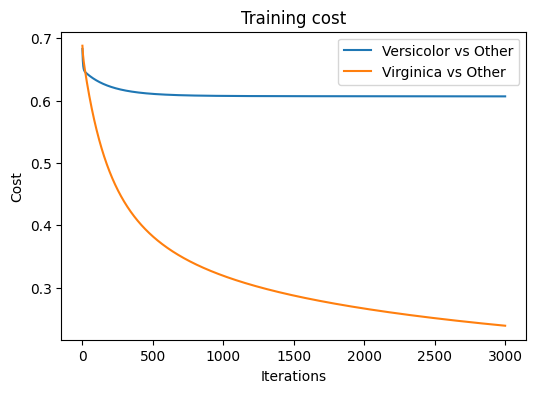

In [46]:
ovr_results = {}
for name, (Xtr, Xte, ytr, yte) in datasets_ovr.items():
    W, loss = train(0.01, 3000, Xtr, ytr)
    cm, acc = evaluate(Xte, yte, W)
    ovr_results[name] = (W, loss, cm, acc)
    print(f"{name} vs Other — final weights [w0, w_sepal, w_petal]: {W}")

plt.figure(figsize=(6, 4))
for name in cases:
    plt.plot(ovr_results[name][1], label=f'{name} vs Other')
plt.xlabel('Iterations'); plt.ylabel('Cost'); plt.legend(); plt.title('Training cost')
plt.show()

Versicolor vs Other: test accuracy = 66.67%, final training cost = 0.6067
[[ 0 10]
 [ 0 20]]
Virginica vs Other: test accuracy = 90.00%, final training cost = 0.2390
[[10  0]
 [ 3 17]]


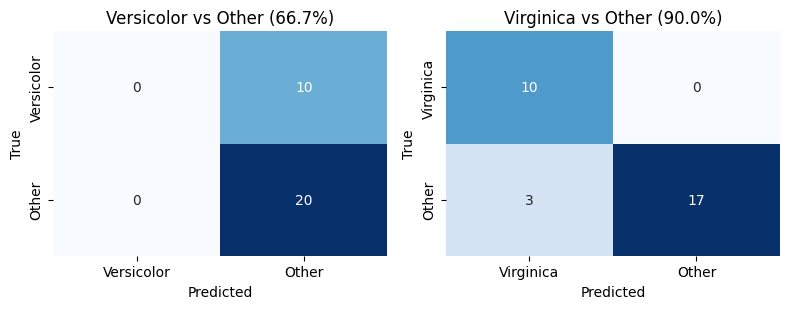

,Target class,w0,w sepal,w petal,Test accuracy (%)
0,Setosa,-0.4938,-1.2356,2.6607,100.00
1,Versicolor,-0.0007,0.4175,-0.4483,66.67
2,Virginica,0.7342,1.6832,-2.3244,90.00


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, name in zip(axes, cases):
    W, loss, cm, acc = ovr_results[name]
    print(f"{name} vs Other: test accuracy = {acc*100:.2f}%, final training cost = {loss[-1]:.4f}")
    print(cm)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=[name, 'Other'], yticklabels=[name, 'Other'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{name} vs Other ({acc*100:.1f}%)')
plt.tight_layout(); plt.show()

acc_setosa = evaluate(X_test, y_test, W_setosa)[1]
summary = [['Setosa', *np.round(W_setosa, 4), round(acc_setosa * 100, 2)]]
summary += [[n, *np.round(ovr_results[n][0], 4), round(ovr_results[n][3] * 100, 2)] for n in cases]
pd.DataFrame(summary, columns=['Target class', 'w0', 'w sepal', 'w petal', 'Test accuracy (%)'])

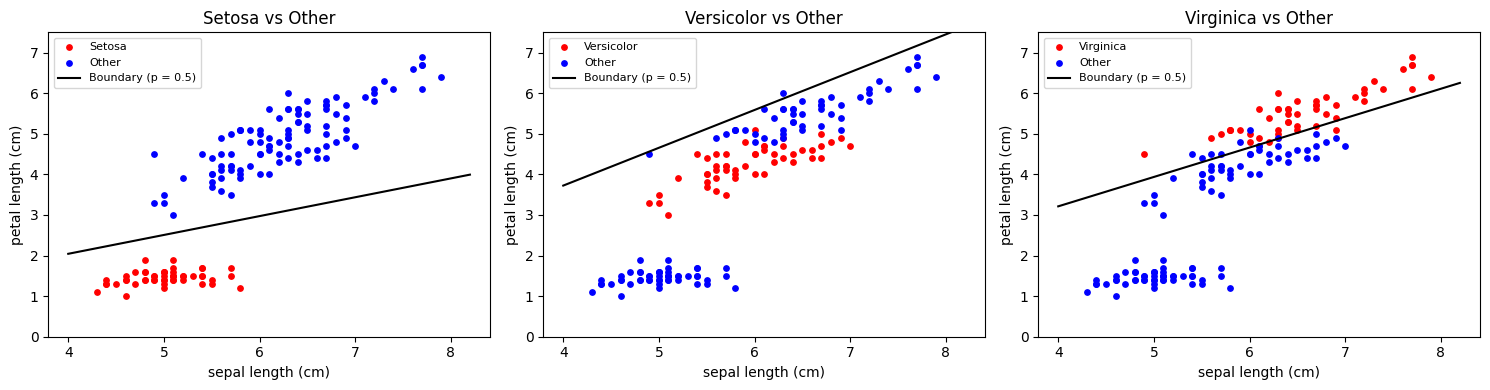

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
all_cases = {'Setosa': (0, W_setosa), 'Versicolor': (1, ovr_results['Versicolor'][0]),
             'Virginica': (2, ovr_results['Virginica'][0])}
xs = np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 50)
for ax, (name, (cls, W)) in zip(axes, all_cases.items()):
    tgt = labels == cls
    ax.scatter(X[tgt, 1], X[tgt, 2], c='red', label=name, s=15)
    ax.scatter(X[~tgt, 1], X[~tgt, 2], c='blue', label='Other', s=15)
    ax.plot(xs, -(W[0] + W[1] * xs) / W[2], 'k', label='Boundary (p = 0.5)')
    ax.set_ylim(0, 7.5)
    ax.set_xlabel('sepal length (cm)'); ax.set_ylabel('petal length (cm)')
    ax.set_title(f'{name} vs Other'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Task 3 [40 marks]

In this tutorial, you were introduced to the parameter $\alpha$, also known as the learning rate. A fixed value of $0.01$ was chosen for our algorithm. Your task is to investigate the effect of selecting different values of $\alpha$ for the Iris-Setosa vs. All classifier. In your report, please cover the following aspects:

1. Experiment with different values of $\alpha$ (e.g., 0.0001, 0.1, 1, 100). Note that you may want to print the loss more frequently to observe the initial behavior of the algorithm when using different $\alpha$ values.

2. Run the code for each of the specified $\alpha$ values and record the performance of the network for each case.

3. Include a graphical representation of the cost versus epochs for each $\alpha$ value. Additionally, report the accuracy of the test data and provide confusion matrices for each $\alpha$ value.

4. In your own words, explain why the performance of the algorithm changes when using different $\alpha$ values. Discuss the effect of the learning rate on the gradient descent process, considering aspects like convergence speed, stability, and the risk of overshooting.


In [49]:
# Task 3
alphas = [0.0001, 0.01, 0.1, 1, 100]
num_iter = 3000
lr_results = {}
for a in alphas:
    print(f"\n===== alpha = {a} =====")
    with np.errstate(over='ignore'):           # exp overflow is expected for very large alpha
        W, loss = train(a, num_iter, X_train, y_train, print_every=None)
    for i in [0, 1, 2, 3, 4, 9, 49, 99, 499, 999, 2999]:   # dense early prints, then sparse
        print(f"iteration {i+1:5d}: cost = {loss[i]:.6f}")
    lr_results[a] = (W, loss)


===== alpha = 0.0001 =====
iteration     1: cost = 0.692791
iteration     2: cost = 0.692435
iteration     3: cost = 0.692080
iteration     4: cost = 0.691726
iteration     5: cost = 0.691373
iteration    10: cost = 0.689621
iteration    50: cost = 0.676350
iteration   100: cost = 0.661478
iteration   500: cost = 0.588359
iteration  1000: cost = 0.550687
iteration  3000: cost = 0.499659

===== alpha = 0.01 =====
iteration     1: cost = 0.659663
iteration     2: cost = 0.633806
iteration     3: cost = 0.613676
iteration     4: cost = 0.597837
iteration     5: cost = 0.585218
iteration    10: cost = 0.548830
iteration    50: cost = 0.465758
iteration   100: cost = 0.395588
iteration   500: cost = 0.166322
iteration  1000: cost = 0.095343
iteration  3000: cost = 0.036661

===== alpha = 0.1 =====
iteration     1: cost = 0.538066
iteration     2: cost = 0.516323
iteration     3: cost = 0.498031
iteration     4: cost = 0.480712
iteration     5: cost = 0.464267
iteration    10: cost = 0.3937

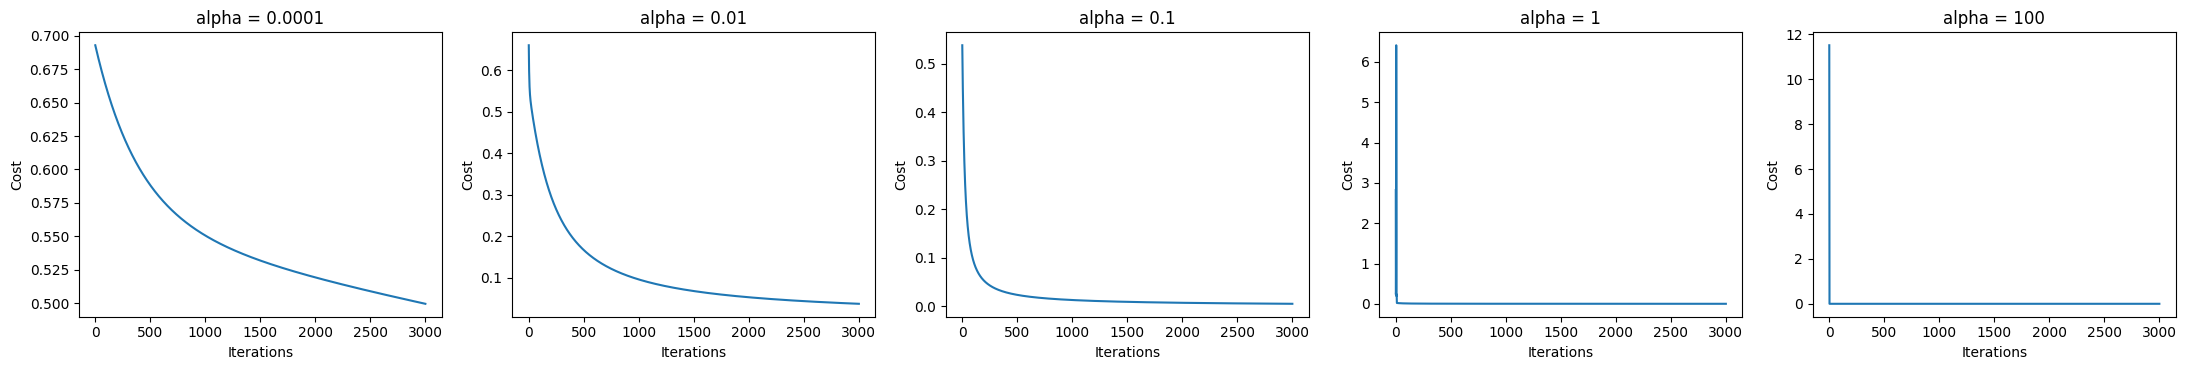

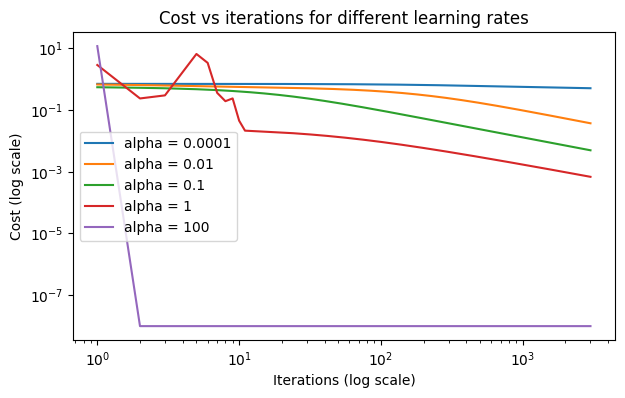

In [50]:
fig, axes = plt.subplots(1, len(alphas), figsize=(22, 3.8))
for ax, a in zip(axes, alphas):
    ax.plot(range(1, num_iter + 1), lr_results[a][1])
    ax.set_title(f'alpha = {a}')
    ax.set_xlabel('Iterations'); ax.set_ylabel('Cost')
plt.tight_layout(); plt.show()

# All on one log-scale plot for direct comparison
plt.figure(figsize=(7, 4))
for a in alphas:
    # floor at 1e-8 only so a cost of exactly 0 (alpha = 100) can be drawn on a log axis
    plt.plot(range(1, num_iter + 1), np.maximum(lr_results[a][1], 1e-8), label=f'alpha = {a}')
plt.xscale('log'); plt.yscale('log'); plt.xlabel('Iterations (log scale)'); plt.ylabel('Cost (log scale)')
plt.title('Cost vs iterations for different learning rates'); plt.legend()
plt.show()

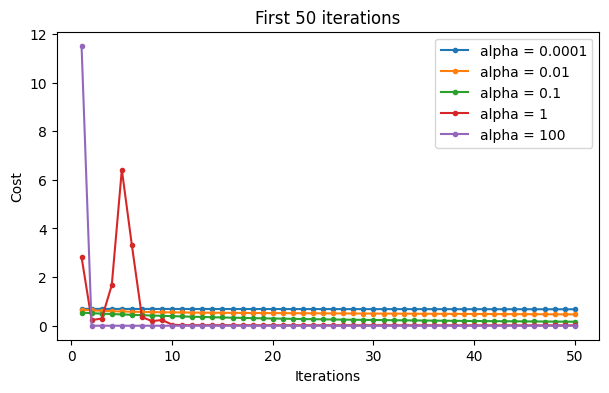

In [51]:
plt.figure(figsize=(7, 4))
for a in alphas:
    plt.plot(range(1, 51), lr_results[a][1][:50], marker='.', label=f'alpha = {a}')
plt.xlabel('Iterations'); plt.ylabel('Cost'); plt.title('First 50 iterations'); plt.legend()
plt.show()

alpha = 0.0001: test accuracy = 66.67%
[[ 0 10]
 [ 0 20]]
alpha = 0.01: test accuracy = 100.00%
[[10  0]
 [ 0 20]]
alpha = 0.1: test accuracy = 100.00%
[[10  0]
 [ 0 20]]
alpha = 1: test accuracy = 100.00%
[[10  0]
 [ 0 20]]
alpha = 100: test accuracy = 100.00%
[[10  0]
 [ 0 20]]


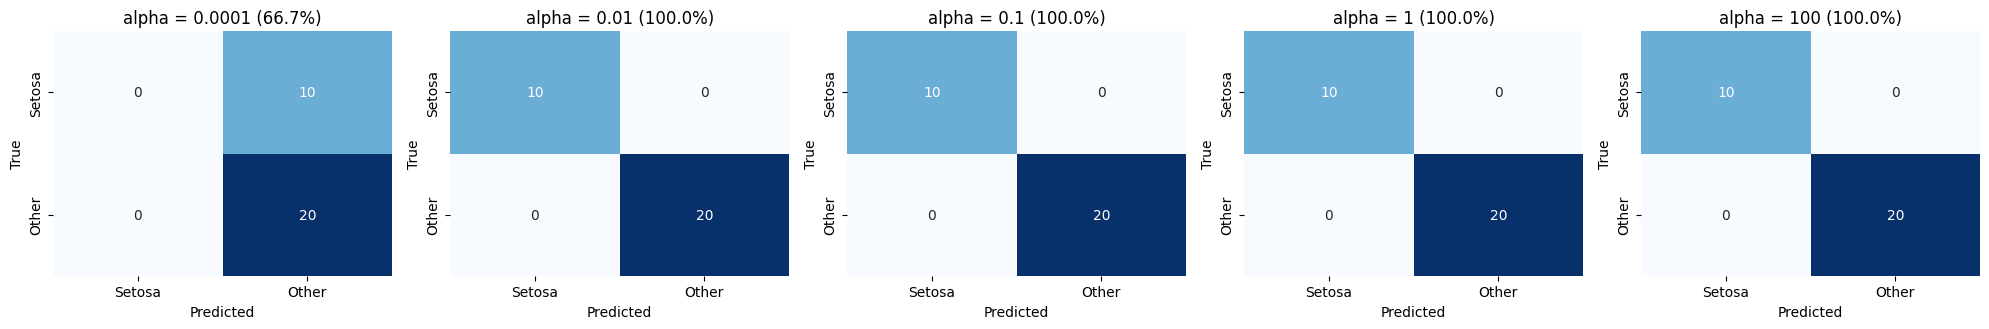

,alpha,w0,w sepal,w petal,Final training cost,Test accuracy (%)
0,0.0001,-0.0032,0.0555,0.1920,0.499659,66.67
1,0.0100,-0.4938,-1.2356,2.6607,0.036661,100.00
2,0.1000,-0.8864,-2.2490,4.8267,0.004900,100.00
3,1.0000,-1.2962,-3.3947,7.3821,0.000679,100.00
4,100.0000,-16.6667,-40.2500,91.7083,-0.000000,100.00


In [52]:
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3.4))
rows = []
for ax, a in zip(axes, alphas):
    W, loss = lr_results[a]
    cm, acc = evaluate(X_test, y_test, W)
    rows.append([a, *np.round(W, 4), round(loss[-1], 6), round(acc * 100, 2)])
    print(f"alpha = {a}: test accuracy = {acc*100:.2f}%\n{cm}")
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Setosa', 'Other'], yticklabels=['Setosa', 'Other'])
    ax.set_title(f'alpha = {a} ({acc*100:.1f}%)'); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout(); plt.show()

pd.DataFrame(rows, columns=['alpha', 'w0', 'w sepal', 'w petal', 'Final training cost', 'Test accuracy (%)'])

Gradient descent updates the weights as w ← w − α∇J(w). The gradient gives the direction of steepest descent, and α sets the step length. The cost function is identical in every run; only the path taken towards its minimum differs.


*   α = 0.0001 (too small): the steps are so short that the cost only fell from 0.693 to 0.500 in 3000 iterations, and the weights stayed close to zero. The model never formed a useful boundary. It predicted “other” for every test sample, so its 66.67% accuracy equals the majority-class rate. The process is stable but converges far too slowly for the iteration budget.
*   α = 0.01 to 1 (well chosen): all three reached 100% test accuracy. A larger α converged faster: the final cost dropped by roughly an order of magnitude for each tenfold increase in α. The cost curves for 0.01 and 0.1 fall smoothly and monotonically.
*   α = 1 (on the edge of stability): the first few iterations oscillate (cost 2.82 → 0.23 → 0.29 → 1.66 → 6.41) before the run settles and converges. The steps are big enough to overshoot the minimum and land higher up on the other side before the iterations dampen.
*  α = 100 (far too large): the first step overshoots massively (cost 11.5, close to the log(ε) clipping value). The weights jump to |w| ≈ 90, and the sigmoid saturates to outputs of exactly 0 or 1, so the reported cost becomes 0. The tiny negative values are an artefact of the ε term. It still reaches 100% only because Setosa is linearly separable. On separable data the logistic cost keeps decreasing as ‖w‖ → ∞ along a separating direction, so huge weights pointing the right way still classify correctly. On classes that overlap, such as Versicolor vs the rest, the same α would oscillate or diverge. The saturated outputs also throw away the probability information that logistic regression is meant to provide, and they cause numerical problems (exp overflow).


Conclusion:
 The learning rate trades speed against stability. A small α is stable but may not converge within a practical number of iterations. A large α makes rapid early progress but risks overshooting, oscillation, divergence and numerical overflow. For this dataset, α between 0.01 and 0.1 converges smoothly and reliably to a perfect classifier. α = 1 is faster but shows early instability, and α = 100 only “works” because the problem is trivially separable. In practice α is chosen by checking that the cost decreases steadily, or by using a learning-rate schedule that takes large steps early and smaller ones near the minimum.